# Phase 02: data understanding

## The auditory subgraph of Johnston's organ in the *Drosophila melanogaster* connectome

This notebook is the data-understanding phase of the project. We organize the work by the phases of CRISP-DM, a standard process model for data-mining projects (Chapman et al., 2000). In the KDD process (Fayyad et al., 1996) this step is the selection of the target data. We start from three public FlyWire files and end with the subgraph that every later phase reads from `data/processed/`.

Every filtering choice made here shapes what comes after. So we make each one with the data in view and write it down. These are the decisions.

1. which neurons count as Johnston's organ,
2. how many synaptic contacts a connection needs before we trust it,
3. how each connection gets its sign (excitatory, inhibitory or modulatory),
4. which neurons form the sensory input layer,
5. which artificial wirings the biological one is compared against.

### Background for readers new to connectomics

A **connectome** is a map of every neuron in a brain and of the connections between them. It is reconstructed from electron-microscopy images. Algorithms trace each neuron through thousands of image slices and find the points where two neurons touch and pass a signal, and people then proofread the result. **FlyWire** is the public connectome of a whole adult fruit-fly brain (Dorkenwald et al., 2024; Schlegel et al., 2024). It was traced in a complete electron-microscopy volume of that brain (Zheng et al., 2018). The reconstruction keeps improving, so each public release is a frozen **snapshot**. We use release **v783** and download its files from Codex, FlyWire's data portal (Matsliah et al., 2023). The data license and the full list of data credits are in [`data/README.md`](../data/README.md).

**Johnston's organ** (JO) is the ear of the fly. It sits in the antenna, and its sensory neurons respond when sound or air currents move the antenna. These JO neurons are the entry point of the circuit we model. Everything the network "hears" arrives through them.

Two words need care, because the rest of the repository depends on them.

- A **synaptic contact** (a synapse) is one physical site where a neuron passes a signal to another neuron. FlyWire detects each contact automatically in the images (Buhmann et al., 2021; Heinrich et al., 2018).
- A **connection** is a directed pair of neurons, A → B. Its **weight** is the number of synaptic contacts from A onto B. In graph language a neuron is a **node** and a connection is an **edge**.

A connection can therefore be made of one contact or of hundreds. The **contact threshold** is the minimum number of contacts a connection needs to stay in the graph. We drop weak connections because a single detected contact may be an error of the detection algorithm. The final circuit has 20,059 connections, and together they contain 338,013 synaptic contacts.

JO neurons come in subgroups, named JO-A to JO-E, that send their fibers to different zones of the brain (Kamikouchi et al., 2009). JO-A and JO-B respond to vibration and sound. JO-C and JO-E respond to slow, static deflections of the antenna, such as those caused by gravity and wind (Kamikouchi et al., 2009; Yorozu et al., 2009). In this project the **JO subtypes** are JO-A and JO-B.

The question behind the project is whether the biological wiring itself helps a network compute. Testing it needs **control topologies**, artificial networks that share everything with the connectome except the pattern of who connects to whom. Section 7 builds two of them.

## 0. Environment and raw data

The first cell loads the shared library `snnlib`, sets the plotting style and lists the three raw files with their sizes.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent))
from snnlib import extraction, graph, DATA_RAW, DATA_PROCESSED, FIGURES, FLYWIRE_SNAPSHOT

FIGURES.mkdir(exist_ok=True)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.titleweight': 'bold', 'font.size': 10})
BLUE, RED, GREEN, PURPLE = '#2E86AB', '#C73E1D', '#3CAEA3', '#7B68A6'

print('FlyWire snapshot:', FLYWIRE_SNAPSHOT)
for f in sorted(DATA_RAW.glob('*.csv.gz')):
    print(f'  {f.name}: {f.stat().st_size/1e6:.1f} MB')

FlyWire snapshot: v783
  classification.csv.gz: 0.9 MB
  connections_buhmann_no_threshold.csv.gz: 212.1 MB
  consolidated_cell_types.csv.gz: 0.9 MB


### Provenance record

`classification.csv.gz` holds the hierarchical annotation of every neuron (Dorkenwald et al., 2024; Schlegel et al., 2024). `consolidated_cell_types.csv.gz` holds cell types (Deutsch et al., 2025; Matsliah et al., 2024; Schlegel et al., 2024). `connections_buhmann_no_threshold.csv.gz` lists the synaptic connections (Buhmann et al., 2021; Heinrich et al., 2018) with their predicted neurotransmitter (Eckstein et al., 2024).

None of them carries a version column. Counting is the only way to check which release we hold, so we record the totals. The connection file has one row per pair of neurons *and* per neuropil. A **neuropil** is a dense region of the brain where neurons make their contacts, and one connection can be spread over several of them.

In [2]:
annot = extraction.load_annotations()
print(f'Annotated neurons: {len(annot):,}')
print(f'Columns: {list(annot.columns)}')

# Synapse count of the connection file (provenance check)
total_synapses, total_rows = 0, 0
for ch in pd.read_csv(DATA_RAW/'connections_buhmann_no_threshold.csv.gz',
                      usecols=['syn_count'], chunksize=3_000_000):
    total_synapses += int(ch.syn_count.sum()); total_rows += len(ch)
print(f'Connection rows (pre→post→neuropil): {total_rows:,}')
print(f'Total synapses: {total_synapses:,}')
print()
print('The published v783 connectome has 139,255 neurons and 54.5 million synapses')
print('(Dorkenwald et al., 2024). The counts agree, so these are the v783 files.')
print('The released synapse table already leaves out synapses with a cleft score')
print('of 50 or less, even though this aggregated file drops that column. What it')
print('does not apply is a minimum number of contacts per connection; see below.')

Annotated neurons: 139,255
Columns: ['root_id', 'flow', 'super_class', 'class', 'sub_class', 'hemilineage', 'side', 'nerve']


Connection rows (pre→post→neuropil): 16,847,997
Total synapses: 54,492,922

The published v783 connectome has 139,255 neurons and 54.5 million synapses
(Dorkenwald et al., 2024). The counts agree, so these are the v783 files.
The released synapse table already leaves out synapses with a cleft score
of 50 or less, even though this aggregated file drops that column. What it
does not apply is a minimum number of contacts per connection; see below.


The annotation table has 139,255 neurons, and the connection file adds up to 54,492,922 synapses in 16,847,997 rows. Both agree with the published figures for v783, 139,255 neurons and 54.5 million synapses (Dorkenwald et al., 2024). Before release, FlyWire also removed every synapse whose cleft score (a confidence value of the synapse detector) was 50 or less, so that quality filter is already in the data. A minimum number of contacts per connection is not. We choose it in Section 2.

## 1. Identifying Johnston's organ

FlyWire places every neuron in a hierarchy of labels (Schlegel et al., 2024). The auditory JO neurons are those with `super_class = sensory`, `class = mechanosensory` and `sub_class = auditory`. In the annotation release we use, that label covers exactly the JO-A and JO-B subtypes; Section 6 checks it against a second annotation table. The other JO subgroups are labeled `wind_gravity`. We leave out JO-C and JO-E, which respond to static deflection, and also JO-D, a small group that responds to both vibration and deflection (Matsuo et al., 2014).

The next cell lists the mechanosensory subclasses for context and then keeps the auditory neurons.

In [3]:
mechano = annot[(annot.super_class=='sensory') & (annot['class']=='mechanosensory')]
print('Mechanosensory subclasses (context of the JO):')
print(mechano.sub_class.value_counts(dropna=False).to_string())

jo = extraction.jo_neurons(annot)
print(f'\nAuditory JO neurons: {len(jo)}')
print('By side: ', dict(jo.side.value_counts()))
print('By nerve:', dict(jo.nerve.value_counts(dropna=False)))

Mechanosensory subclasses (context of the JO):
sub_class
eye_bristle                        1113
wind_gravity                        486
auditory                            393
head_bristle                        304
grooming                            205
NaN                                  97
taste_peg                            75
labial_nerve_sensory_descending       1

Auditory JO neurons: 393
By side:  {'left': np.int64(214), 'right': np.int64(179)}
By nerve: {'AN': np.int64(393)}


There are 393 auditory JO neurons, 214 on the left side of the brain and 179 on the right, all in the antennal nerve (`AN`).

> **About the subtypes.** The `auditory` label groups JO-A and JO-B but does not tell them apart. In `classification.csv.gz` the 393 neurons share the same value in every column except `side`. The distinction is in the cell-type table from Codex (`consolidated_cell_types.csv.gz`), which we bring in in Section 6. That table is what lets us anchor the mapping from sound frequency to neuron on anatomy.

## 2. Contact threshold per connection

The circuit we keep is the JO neurons plus their **partners**. A partner is any neuron that receives at least one contact from a JO neuron, that is, a second-order neuron of the auditory pathway. We keep every connection among all these neurons. This keeps the network anchored to the sensory input. It leaves out neurons that only send input to this set, and the deeper stages of the pathway.

The connection file has no threshold. It includes pairs supported by a single detected contact, and those are the least reliable. FlyWire synapses were detected automatically and were not proofread one by one. A connection made of very few contacts is therefore more likely to be spurious (Buhmann et al., 2021; Dorkenwald et al., 2024). For their own analyses Dorkenwald et al. (2024) keep connections with at least five synapses, and Codex applies the same threshold by default. The authors call this choice "reasonable but arbitrary" and say it should be adapted to each analysis. Before adopting it, we measure what it costs.

One detail matters. A real connection between two neurons can be spread over several neuropils and appear as several rows. Its weight is the **sum** of contacts over all of them, so we merge the rows *before* applying the threshold. Otherwise a strong connection split across neuropils could be thrown away. The next cell does that merge. It then counts, for thresholds from 1 to 20 contacts, how many connections, neurons, JO neurons on each side and contacts survive.

In [4]:
jo_ids = set(jo.root_id)
raw_rows, partners = extraction.subgraph_connections(jo_ids)
print(f'Second-order postsynaptic partners: {len(partners)}')
print(f'Subgraph nodes (JO ∪ partners):     {len(jo_ids)+len(partners)}')
print(f'Internal rows (pre→post→neuropil):  {len(raw_rows):,}')

agg = (raw_rows.groupby(['pre_root_id','post_root_id'], as_index=False)['syn_count']
       .sum().rename(columns={'syn_count':'weight'}))
print(f'Unique connections after merging:   {len(agg):,}  '
      f'(collapse {len(raw_rows)/len(agg):.2f}×)')

rows = []
for u in [1,2,3,5,10,20]:
    e = agg[agg.weight>=u]
    node_set = set(e.pre_root_id)|set(e.post_root_id)
    jo_g = jo_ids & node_set
    side = jo[jo.root_id.isin(jo_g)].side.value_counts()
    rows.append(dict(threshold=u, edges=len(e), nodes=len(node_set),
                     JO_in_graph=len(jo_g),
                     JO_left=int(side.get('left',0)), JO_right=int(side.get('right',0)),
                     contacts=int(e.weight.sum())))
threshold_sweep_table = pd.DataFrame(rows)
threshold_sweep_table

Second-order postsynaptic partners: 972
Subgraph nodes (JO ∪ partners):     1365
Internal rows (pre→post→neuropil):  108,374
Unique connections after merging:   71,621  (collapse 1.51×)


,threshold,edges,nodes,JO_in_graph,JO_left,JO_right,contacts
0,1,71621,1361,389,212,177,426087
1,2,41881,1339,367,193,174,396347
2,3,30569,1310,338,170,168,373723
3,5,20059,1239,269,124,145,338013
4,10,10475,1075,139,57,82,275227
5,20,4777,891,33,16,17,198660


The JO neurons have 972 partners, so the starting set has 1,365 neurons. Their 108,374 internal rows merge into 71,621 distinct connections. In the table, `edges` counts connections, `nodes` counts neurons, and `contacts` adds up the weights.

The table goes against a natural assumption. The threshold **does** remove JO neurons, and quite a few. Of the 393 annotated auditory neurons, 389 have at least one connection inside the subgraph, and the five-contact threshold keeps 269. It loses **120 of the 389 present (−30.8 %)**, or 124 of the 393 annotated (−31.6 %) if we also count the four that never had a connection. We always give the two figures with their base. The lost neurons are JO neurons whose connections are all weak.

The loss is not symmetric either. The left side loses much more than the right (next cell). The FlyWire papers report a similar reconstruction completeness in both hemispheres (Dorkenwald et al., 2024), so they do not explain the difference. Technical causes are possible. The JO neurons of the two hemispheres were annotated in different detail, and sample artifacts are more frequent in sensory neurons (Schlegel et al., 2024). Biological variability cannot be ruled out either. Whatever the cause, the difference shapes the input layer, so we report it as a limitation.

Threshold 1 → 5:  JO 389 → 269 (-30.8 %)
  left side:  212 → 124 (-41.5 %)
  right side: 177 → 145 (-18.1 %)


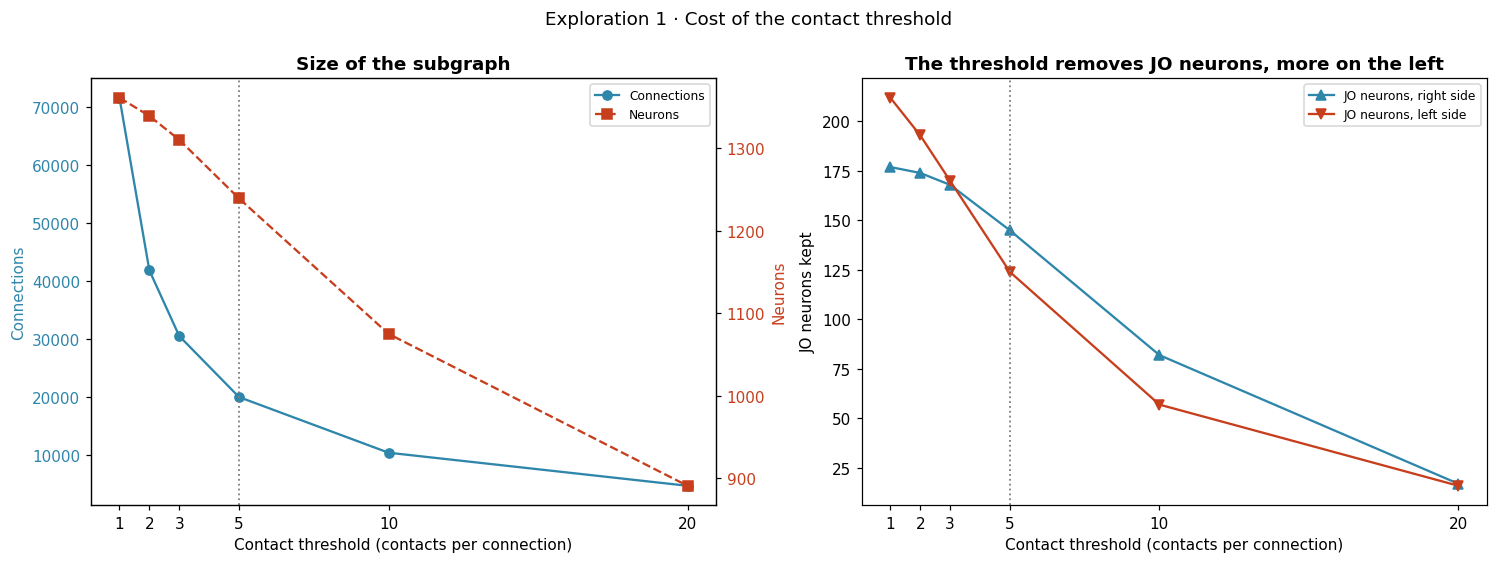

In [5]:
p1 = threshold_sweep_table[threshold_sweep_table.threshold==1].iloc[0]
p5 = threshold_sweep_table[threshold_sweep_table.threshold==5].iloc[0]
print(f'Threshold 1 → 5:  JO {p1.JO_in_graph} → {p5.JO_in_graph} '
      f'({100*(p5.JO_in_graph-p1.JO_in_graph)/p1.JO_in_graph:+.1f} %)')
print(f'  left side:  {p1.JO_left} → {p5.JO_left} '
      f'({100*(p5.JO_left-p1.JO_left)/p1.JO_left:+.1f} %)')
print(f'  right side: {p1.JO_right} → {p5.JO_right} '
      f'({100*(p5.JO_right-p1.JO_right)/p1.JO_right:+.1f} %)')

fig, ax = plt.subplots(1, 2, figsize=(13.5, 4.6), layout='constrained')
ax[0].plot(threshold_sweep_table.threshold, threshold_sweep_table.edges, 'o-', color=BLUE, label='Connections')
ax[0].set_xlabel('Contact threshold (contacts per connection)'); ax[0].set_ylabel('Connections', color=BLUE)
ax[0].tick_params(axis='y', labelcolor=BLUE)
b = ax[0].twinx(); b.plot(threshold_sweep_table.threshold, threshold_sweep_table.nodes, 's--', color=RED, label='Neurons')
b.set_ylabel('Neurons', color=RED); b.tick_params(axis='y', labelcolor=RED)
ax[0].axvline(5, color='gray', ls=':', lw=1.2); ax[0].set_title('Size of the subgraph')
ax[0].set_xticks(threshold_sweep_table.threshold); ax[1].set_xticks(threshold_sweep_table.threshold)
h0, l0 = ax[0].get_legend_handles_labels(); h1, l1 = b.get_legend_handles_labels()
ax[0].legend(h0 + h1, l0 + l1, fontsize=8, loc='upper right')

ax[1].plot(threshold_sweep_table.threshold, threshold_sweep_table.JO_right, '^-', color=BLUE, label='JO neurons, right side')
ax[1].plot(threshold_sweep_table.threshold, threshold_sweep_table.JO_left, 'v-', color=RED, label='JO neurons, left side')
ax[1].axvline(5, color='gray', ls=':', lw=1.2)
ax[1].set_xlabel('Contact threshold (contacts per connection)'); ax[1].set_ylabel('JO neurons kept')
ax[1].set_title('The threshold removes JO neurons, more on the left')
ax[1].legend(fontsize=8)
fig.suptitle('Exploration 1 · Cost of the contact threshold', y=1.08)
fig.savefig(FIGURES/'02-contact-threshold-cost.png'); plt.show()

In the figure, the left panel shows how the graph shrinks as the threshold grows. Connections fall fast, neurons more slowly. The right panel follows the JO neurons of each side. The dotted line marks five contacts. Between one and five contacts the left side goes from 212 to 124 JO neurons (−41.5 %) and the right side from 177 to 145 (−18.1 %).

**Decision.** We adopt a threshold of **at least 5 contacts per connection**. Its cost is measured above, and the value was fixed before running any model, which keeps the choice independent of the results. Lowering it to keep more JO neurons would bring in single-contact connections, the least reliable ones. The left–right imbalance stays recorded as a limitation. Phase 04 later tests the choice by rebuilding the subgraph at 1, 3, 5 and 10 contacts and rerunning the whole task (see the [modeling results](../04-modeling/results.md)).

## 3. Neurotransmitter and polarity

A neuron acts on its targets through a chemical messenger, its **neurotransmitter**, and the transmitter sets the sign of the effect. FlyWire provides a neurotransmitter prediction for every synapse, made by a classifier that looks at the electron-microscopy image of the synapse (Eckstein et al., 2024). To simulate the circuit we turn the prediction into a **polarity**, the effect of a connection on its target. An excitatory connection pushes the target towards firing and an inhibitory one holds it back. A modulatory connection, in biology, slowly changes how strongly its target responds; the model gives it a separate slow channel. For acetylcholine, GABA and glutamate we follow the sign convention of Dorkenwald et al. (2024).

| Neurotransmitter | Polarity | Channel in the model |
|---|---|---|
| ACH (acetylcholine) | Excitatory | `I_exc`, τ = 5 ms |
| GABA, GLUT (glutamate) | Inhibitory | `I_inh`, τ = 10 ms |
| SER, DA, OCT (serotonin, dopamine, octopamine) | Modulatory | `I_mod`, τ = 50 ms |

Glutamate counts as inhibitory. In the central brain of *Drosophila* most known glutamatergic synapses inhibit their target through GluClα chloride channels (Eckstein et al., 2024; Liu & Wilson, 2013), unlike the mainly excitatory role of glutamate in vertebrates, although excitatory glutamate transmission also exists in flies. The separate modulatory channel is a choice of this project. Phase 03 tests what it does.

The delicate question is **at what level** the transmitter is assigned. Dale's principle states that a neuron releases the same transmitter, or the same set of transmitters, at all of its terminals (Eccles, 1976; Svensson et al., 2019). The transmitter is then a property of the **presynaptic neuron**, not of each connection. The next cell checks whether the per-synapse predictions agree within each neuron of the subgraph.

In [6]:
print("Do the data follow Dale's principle?")
mixed_nt = raw_rows.groupby('pre_root_id').nt_type.nunique()
print(f'  Presynaptic neurons in the subgraph: {len(mixed_nt):,}')
print(f'  With more than one nt_type among their rows: {int((mixed_nt>1).sum()):,} '
      f'({100*(mixed_nt>1).mean():.1f} %)')
pairs = raw_rows.groupby(['pre_root_id','post_root_id']).nt_type.nunique()
print(f'  (pre, post) pairs whose nt_type differs across neuropils: '
      f'{int((pairs>1).sum()):,} of {len(pairs):,} ({100*(pairs>1).mean():.1f} %)')
print()
print('They do not: the prediction is made per synapse and it is noisy. Taking the')
print('nt of the FIRST row of each group would make the polarity depend on the row')
print('order of the file. We assign it per neuron instead, by a majority vote')
print('weighted by synapse count over the WHOLE connectome.')

Do the data follow Dale's principle?
  Presynaptic neurons in the subgraph: 1,303
  With more than one nt_type among their rows: 1,183 (90.8 %)
  (pre, post) pairs whose nt_type differs across neuropils: 6,656 of 71,621 (9.3 %)

They do not: the prediction is made per synapse and it is noisy. Taking the
nt of the FIRST row of each group would make the polarity depend on the row
order of the file. We assign it per neuron instead, by a majority vote
weighted by synapse count over the WHOLE connectome.


The predictions disagree inside most neurons. Of the 1,303 presynaptic neurons of the subgraph, 1,183 (90.8 %) carry more than one label, and 9.3 % of the neuron pairs get different labels in different neuropils. The classifier works synapse by synapse and makes mistakes. Taking the label of the first row would therefore make the sign of part of the graph depend on the order of the rows in the CSV file.

We assign one transmitter per neuron instead, by a majority vote weighted by the number of synapses over the whole connectome, as Eckstein et al. (2024) do to get neuron-level predictions. Ties are broken in a fixed order, so the result does not depend on the file. The **purity** of a neuron is the fraction of its synapses that agree with the winning transmitter. The next cell computes it and counts how many connections of the final graph change sign between the two criteria.

In [7]:
nt_by_neuron = extraction.nt_per_neuron()
print(f'Dominant neurotransmitter estimated for {len(nt_by_neuron):,} neurons')
print(f'  Mean purity (fraction of synapses that support the dominant one): {nt_by_neuron.purity.mean():.3f}')
print(f'  Neurons with purity < 0.5: {int((nt_by_neuron.purity<0.5).sum()):,}')
print('  Breakdown:', dict(nt_by_neuron.neuron_nt.value_counts()))

# The two criteria compared on the same connections
cmp = agg.copy()
cmp['nt_first_row'] = raw_rows.groupby(['pre_root_id','post_root_id']).nt_type.first().values
cmp['neuron_nt'] = cmp.pre_root_id.map(nt_by_neuron.neuron_nt)
POL = extraction.POLARITY
f5 = cmp[cmp.weight>=5]
changed = (f5.nt_first_row.map(POL) != f5.neuron_nt.map(POL)).sum()
print(f'\nOn the {len(f5):,} connections of the final graph:')
print(f'  connections whose POLARITY changes from "first row" to "per-neuron majority": '
      f'{changed:,} ({100*changed/len(f5):.1f} %)')

Dominant neurotransmitter estimated for 138,005 neurons
  Mean purity (fraction of synapses that support the dominant one): 0.866
  Neurons with purity < 0.5: 3,631
  Breakdown: {'ACH': np.int64(90801), 'GLUT': np.int64(24835), 'GABA': np.int64(19145), 'SER': np.int64(2093), 'DA': np.int64(906), 'OCT': np.int64(225)}

On the 20,059 connections of the final graph:
  connections whose POLARITY changes from "first row" to "per-neuron majority": 1,258 (6.3 %)


The per-neuron assignment covers 138,005 neurons, with a mean purity of 0.866. In other words, on average about 13 % of the synapses of a neuron carry a label other than the winner. Only 3,631 neurons have a purity below 0.5. In the final graph, 1,258 connections (6.3 %) change sign when we move from the first-row label to the per-neuron majority. That is the size of the error the first-row shortcut would have introduced.

### Most JO afferents are cholinergic

The JO neurons are afferents, which means they carry sensory signals into the brain. Most of them are cholinergic (Ishikawa et al., 2017), so they excite their targets. The transmitter classifier, however, is less reliable for some first-order sensory neurons and mislabels several of them as serotonergic (Eckstein et al., 2024). Keeping those labels would make part of the input pathway inhibitory or modulatory, right where the stimulus enters the network.

The next cell measures the problem **on the final graph**, the 960 JO → partner connections that survive the threshold. The correction itself is applied earlier, on the 71,621 merged connections, so the count that `build()` prints in Section 4 is larger, **757 afferent connections reassigned**. Both numbers describe the same decision, counted at two points of the pipeline.

In [8]:
jo_edges = f5[f5.pre_root_id.isin(jo_ids)]
by_nt = jo_edges.neuron_nt.value_counts()
non_ach = int((jo_edges.neuron_nt!='ACH').sum())
print(f'Outgoing connections of JO neurons in the final graph: {len(jo_edges)}')
print('  by estimated neurotransmitter:', dict(by_nt))
print(f'  non-cholinergic: {non_ach} ({100*non_ach/len(jo_edges):.1f} % of the connections, '
      f'{100*jo_edges[jo_edges.neuron_nt!="ACH"].weight.sum()/jo_edges.weight.sum():.1f} % of the weight)')
print()
print('We apply a biological prior: every connection whose presynaptic neuron is a')
print('JO neuron enters as ACH / Excitatory. The prediction of Eckstein et al. (2024)')
print('is kept unchanged for every other neuron.')

Outgoing connections of JO neurons in the final graph: 960
  by estimated neurotransmitter: {'ACH': np.int64(896), 'SER': np.int64(53), 'GABA': np.int64(11)}
  non-cholinergic: 64 (6.7 % of the connections, 6.6 % of the weight)

We apply a biological prior: every connection whose presynaptic neuron is a
JO neuron enters as ACH / Excitatory. The prediction of Eckstein et al. (2024)
is kept unchanged for every other neuron.


Of the 960 outgoing JO connections, 64 (6.7 % of them, carrying 6.6 % of their weight) were predicted as serotonin or GABA. We call the fix the **cholinergic prior**. Every connection that leaves a JO neuron is set to acetylcholine, and the prediction stays as it is for every other neuron. The column `nt_source` of the connection table records which connections carry the prior. One caveat remains. JO neurons also make electrical synapses onto some central targets (Azevedo & Wilson, 2017; Pézier et al., 2016), and a connectome of chemical synapses does not contain them.

## 4. Building the canonical subgraph

The shared library wraps all the steps above in one function, `extraction.build()`, which writes the three files of `data/processed/`. `jo_nodes.csv` has one row per neuron, `jo_edges.csv` one row per connection (weight, neurotransmitter, purity, origin of the neurotransmitter and polarity), and `jo_meta.json` the summary counts. The data stage of the pipeline calls the same function, so the notebook and the pipeline write identical files. The function prints each step as it runs.

In [9]:
nodes, edges, meta = extraction.build()

1. JO neurons (auditory): 393   {'left': np.int64(214), 'right': np.int64(179)}


2. Second-order postsynaptic partners: 972
3. Internal rows (pre→post→neuropil): 108,374
   Unique connections after merging neuropils: 71,621 (collapse 1.51×)


4. NT per neuron: mean purity 0.866
5. JO cholinergic prior: 757 afferent edges reassigned to ACH
6. Threshold ≥5: 20,059 connections, 1239 nodes, 269 JO
7. Input layer = JO neurons with outgoing connections (out-degree > 0): 123
8. Cell subtype: 123/123 input neurons typed {'JO-B': np.int64(87), 'JO-A': np.int64(36)}

Saved to data/processed/  (jo_nodes.csv, jo_edges.csv, jo_meta.json)


In [10]:
print(json.dumps(meta, indent=2, ensure_ascii=False))

{
  "flywire_snapshot": "v783",
  "min_contacts": 5,
  "n_jo_total": 393,
  "n_partners": 972,
  "n_nodes": 1239,
  "n_jo_in_graph": 269,
  "n_jo_input": 123,
  "n_edges": 20059,
  "edges_by_polarity": {
    "Inhibitory": 11437,
    "Excitatory": 8512,
    "Modulatory": 110
  },
  "jo_edges_reassigned_to_ach": 757,
  "total_weight": 338013,
  "jo_input_by_side": {
    "right": 82,
    "left": 41
  },
  "jo_input_by_subtype": {
    "JO-B": 87,
    "JO-A": 36
  }
}


The subgraph has 1,239 neurons and 20,059 connections, which contain 338,013 synaptic contacts in total. It keeps 269 JO neurons, and 123 of them form the input layer (Section 6 explains why only those). By polarity there are 11,437 inhibitory, 8,512 excitatory and 110 modulatory connections. These three files are what phases 03 to 06 read.

## 5. Topological characterization

With the graph built, we describe its shape. **Topology** here means the pattern of who connects to whom, regardless of the weights. Later we compare these same metrics against the control topologies. If the biological circuit looked like a random network on all of them, the research question of this project would have little to work with.

| Metric | What it measures |
|---|---|
| Density | fraction of all possible directed connections that exist |
| Mean degree | connections per neuron (the mean number of outgoing connections, equal to the mean number of incoming ones) |
| Reciprocity | fraction of connections A → B for which B → A also exists |
| Mean clustering | how often two neighbors of a neuron are also connected to each other, averaged over neurons (on the undirected graph) |
| Weakly connected components | pieces of the network that cannot reach each other even when the direction of connections is ignored |
| Communities (Louvain) | groups found by the Louvain method, which splits the undirected graph into densely connected groups (Blondel et al., 2008); its random seed is fixed to 42 |
| Modularity Q | how strong that split is: high when there are many connections inside the groups and few between them (Newman, 2006) |
| E/I ratio | excitatory connections divided by inhibitory connections |

In [11]:
C = graph.load()
G = nx.DiGraph()
G.add_nodes_from(range(C.N))
G.add_edges_from(zip(C.pre.tolist(), C.post.tolist()))
Gu = G.to_undirected()

exc = int(C.mask['Excitatory'].sum()); inh = int(C.mask['Inhibitory'].sum())
communities = nx.community.louvain_communities(Gu, seed=42)
Q = nx.community.modularity(Gu, communities)

metrics = {
    'Nodes': C.N, 'Edges': len(C.pre),
    'JO neurons': int(C.is_jo.sum()), 'Input layer (JO with output)': C.N_input,
    'Density': nx.density(G),
    'Mean degree': len(C.pre)/C.N,
    'Reciprocity': nx.reciprocity(G),
    'Mean clustering': nx.average_clustering(Gu),
    'Weakly connected components': nx.number_weakly_connected_components(G),
    'Communities (Louvain)': len(communities),
    'Modularity Q': Q,
    'E/I ratio': exc/inh,
}
for k,v in metrics.items():
    print(f'  {k:28s} {v:,.4f}' if isinstance(v,float) else f'  {k:28s} {v:,}')

  Nodes                        1,239
  Edges                        20,059
  JO neurons                   269
  Input layer (JO with output) 123
  Density                      0.0131
  Mean degree                  16.1897
  Reciprocity                  0.1287
  Mean clustering              0.1835
  Weakly connected components  1
  Communities (Louvain)        5
  Modularity Q                 0.3524
  E/I ratio                    0.7443


The circuit is sparse, with a density of 0.0131 and a mean degree of 16.1897 connections per neuron. It forms a single weakly connected component, so there are no isolated islands. Reciprocity is 0.1287 and mean clustering 0.1835. Inhibition dominates. The E/I ratio is 0.7443, roughly three excitatory connections for every four inhibitory ones.

**Modularity, Q = 0.3524, is the number that carries the most weight.** Louvain finds 5 communities, and a value like this means that the circuit is organized in blocks densely wired inside and loosely wired between them. Random wiring does not produce that. It is the first number that describes the structure phase 04 puts to the test. If the biological topology helps the network, the advantage has to come from features like this one.

## 6. The input layer: which JO neurons can pass the stimulus on

A JO neuron passes the stimulus on only if it has at least one **outgoing** connection in the graph. The **out-degree** of a neuron is its number of outgoing connections, and the in-degree counts the incoming ones. The contact threshold removes weak outgoing connections, so it can leave JO neurons that receive connections but send none. We check this before injecting any stimulus.

In [12]:
jo_idx = np.where(C.is_jo)[0]
out_degree = np.bincount(C.pre, minlength=C.N)
input_jo = C.is_jo & (out_degree>0)
print(f'JO neurons in the graph:             {int(C.is_jo.sum())}')
print(f'  with out-degree > 0 (input layer): {int(input_jo.sum())}')
print(f'  without outputs (receive only):    {int((C.is_jo & (out_degree==0)).sum())} '
      f'({100*(C.is_jo & (out_degree==0)).sum()/C.is_jo.sum():.1f} %)')

is_jo_pre = C.is_jo[C.pre]; is_jo_post = C.is_jo[C.post]
print(f'\nConnections JO → JO:       {int((is_jo_pre & is_jo_post).sum())}')
print(f'Connections JO → partner:  {int((is_jo_pre & ~is_jo_post).sum())}')
print(f'Connections partner → JO:  {int((~is_jo_pre & is_jo_post).sum())}  (central feedback)')
print()
print('More than half of the JO neurons in the graph have no outgoing connection;')
print('they are in it only because they receive connections. Injecting the stimulus')
print('into them would send it into a dead end and, worse, spread it unevenly over')
print('the frequency channels. The input layer is the JO neurons with outputs.')
print(f'\nFinal input layer: {C.N_input} neurons, by side '
      f'{meta["jo_input_by_side"]}')

JO neurons in the graph:             269
  with out-degree > 0 (input layer): 123
  without outputs (receive only):    146 (54.3 %)

Connections JO → JO:       0
Connections JO → partner:  960
Connections partner → JO:  698  (central feedback)

More than half of the JO neurons in the graph have no outgoing connection;
they are in it only because they receive connections. Injecting the stimulus
into them would send it into a dead end and, worse, spread it unevenly over
the frequency channels. The input layer is the JO neurons with outputs.

Final input layer: 123 neurons, by side {'right': 82, 'left': 41}


Only 123 of the 269 JO neurons in the graph (45.7 %) have an outgoing connection. The other 146 (54.3 %) are there only because central neurons send them feedback, 698 connections in total. There are no JO → JO connections. The 960 JO → partner connections all come from those 123 neurons, 7.8 per neuron on average and 33 at most. Over the 20,059 connections of the graph, the entry pathway accounts for 4.8 % and the feedback onto JO neurons for 3.5 %. The remaining 18,401 connections (91.7 %) run between partners, so most of the circuit is central processing.

The **input layer** is therefore the 123 JO neurons with outgoing connections, 82 on the right side and 41 on the left. The other 146 stay in the network, because the feedback they receive is real, but they get no stimulus. This matters for the frequency channels of phase 04, where a bank of 32 band-pass filters splits the sound into frequency bands and each band drives a block of input neurons. Spread over the 123 neurons of the input layer, every channel gets 3 or 4 of them. Spread over all 269 JO neurons, some channels would get many more useful neurons than others.

### The JO-A and JO-B subtypes: anchoring the frequency mapping

Johnston's organ is not uniform. JO-A and JO-B are the vibration-sensitive subgroups, and they project to separate zones of the AMMC (antennal mechanosensory and motor center), the first relay of the auditory pathway. JO-B prefers low-frequency vibrations, below about 100 Hz, while JO-A carries the high-frequency responses (Kamikouchi et al., 2009; Matsuo et al., 2014). We use this difference only as a coarse, two-level anchor. The filterbank channels go to JO-B neurons at the low end and to JO-A neurons at the high end, instead of being assigned arbitrarily.

The next cell reads the cell-type table and checks that its JO-A and JO-B labels cover the same 393 neurons as the `auditory` subclass.

In [13]:
cell_types = extraction.load_cell_types()
jo_all = jo.merge(cell_types, on='root_id', how='left')
print('Cell subtype of the 393 auditory JO neurons:')
print(f'  with an assigned type: {jo_all.primary_type.notna().sum()} / {len(jo_all)}')
print(' ', dict(jo_all.primary_type.value_counts()))
print('\nDoes the "auditory" subclass match JO-A + JO-B?')
ab = set(cell_types[cell_types.primary_type.isin(['JO-A','JO-B'])].root_id)
print(f'  JO-A + JO-B in the whole connectome: {len(ab)}')
print(f'  sub_class == auditory:               {len(jo_ids)}')
print(f'  same set?                            {ab == set(jo_ids)}')
print('\nIn our subgraph:')
print('  JO in the graph:', dict(C.nodes[C.nodes.is_jo].cell_type.value_counts()))
print('  Input layer:    ', dict(C.nodes[C.nodes.is_input].cell_type.value_counts()))
print()
print(pd.crosstab(C.nodes[C.nodes.is_input].cell_type,
                  C.nodes[C.nodes.is_input].side).to_string())

Cell subtype of the 393 auditory JO neurons:
  with an assigned type: 393 / 393
  {'JO-B': np.int64(299), 'JO-A': np.int64(94)}

Does the "auditory" subclass match JO-A + JO-B?
  JO-A + JO-B in the whole connectome: 393
  sub_class == auditory:               393
  same set?                            True

In our subgraph:
  JO in the graph: {'JO-B': np.int64(187), 'JO-A': np.int64(82)}
  Input layer:     {'JO-B': np.int64(87), 'JO-A': np.int64(36)}

side       left  right
cell_type             
JO-A          7     29
JO-B         34     53


All 393 neurons have a subtype, 299 JO-B and 94 JO-A. The `auditory` subclass is exactly the set JO-A + JO-B. They are the same neurons, not just the same count. A second annotation table thus agrees with the choice made in Section 1. In the subgraph, 187 JO-B and 82 JO-A neurons remain, and the input layer has 87 JO-B and 36 JO-A. JO-A is strongly lateralized in the input layer, with 29 neurons on the right side and 7 on the left.

### Are JO-A and JO-B different in these data?

A label is only useful if it matches a real difference. We test it by asking whether neurons of the same subtype send their connections to more similar targets than neurons of different subtypes. For each input neuron we build its **projection profile**, the number of contacts it makes onto each partner. We normalize the profiles and compute the cosine similarity between every pair of neurons. A value of 1 means the same targets in the same proportions, and 0 means no shared target. Then we average the similarity within JO-A, within JO-B and between the two.

Projection-profile similarity:
  within JO-A:     0.1205
  within JO-B:     0.0369
  between A and B: 0.0163
  within/between ratio = 4.84x

The two subtypes form genuinely different projection groups; the label is not
decorative. That is what makes the tonotopic anchor usable.


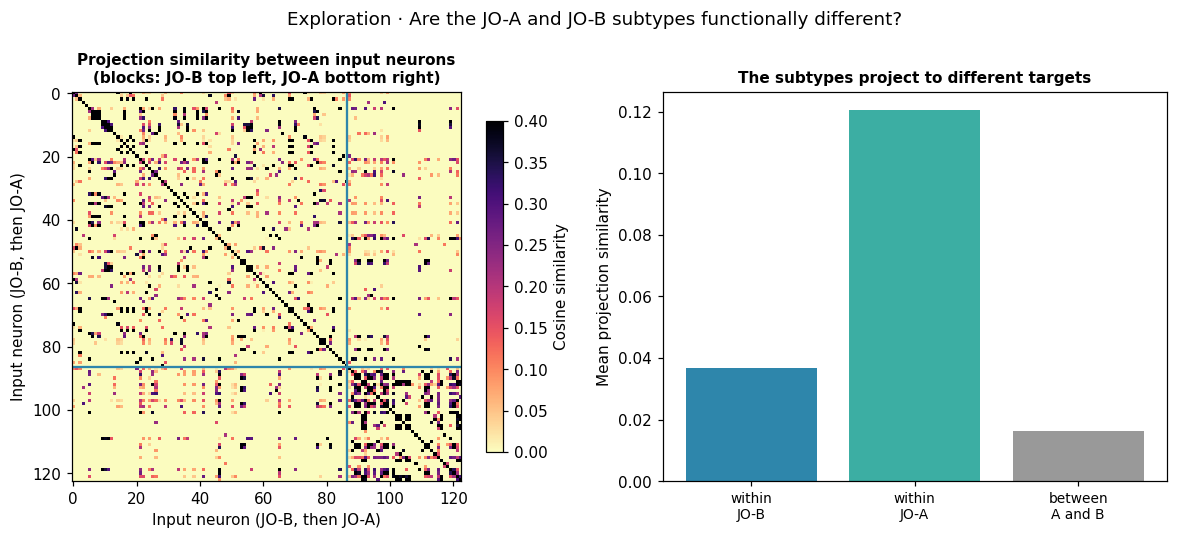

In [14]:
input_idx = C.input_idx
partner_idx = np.where(~C.is_jo)[0]
partner_pos = {n:i for i,n in enumerate(partner_idx)}
input_pos = {n:i for i,n in enumerate(input_idx)}
P = np.zeros((len(input_idx), len(partner_idx)))
for a,b,w in zip(C.pre, C.post, C.raw_weight):
    if a in input_pos and b in partner_pos:
        P[input_pos[a], partner_pos[b]] += w
Pn = P/np.maximum(np.linalg.norm(P,axis=1,keepdims=True),1e-9)
S = Pn@Pn.T
input_type_arr = np.asarray(C.input_type, dtype=object)
mA, mB = input_type_arr=='JO-A', input_type_arr=='JO-B'
sAA = S[np.ix_(mA,mA)].copy(); np.fill_diagonal(sAA, np.nan)
sBB = S[np.ix_(mB,mB)].copy(); np.fill_diagonal(sBB, np.nan)
sAB = S[np.ix_(mA,mB)]
within = (np.nanmean(sAA)+np.nanmean(sBB))/2
print('Projection-profile similarity:')
print(f'  within JO-A:     {np.nanmean(sAA):.4f}')
print(f'  within JO-B:     {np.nanmean(sBB):.4f}')
print(f'  between A and B: {np.nanmean(sAB):.4f}')
print(f'  within/between ratio = {within/max(np.nanmean(sAB),1e-9):.2f}x')
print()
print('The two subtypes form genuinely different projection groups; the label is not')
print('decorative. That is what makes the tonotopic anchor usable.')

fig, ax = plt.subplots(1,2, figsize=(13,4.6))
order = np.concatenate([np.where(mB)[0], np.where(mA)[0]])
im = ax[0].imshow(S[np.ix_(order,order)], cmap='magma_r', vmin=0, vmax=.4)
ax[0].axhline(mB.sum()-.5, color=BLUE, lw=1.5); ax[0].axvline(mB.sum()-.5, color=BLUE, lw=1.5)
ax[0].set_title('Projection similarity between input neurons\n(blocks: JO-B top left, JO-A bottom right)', fontsize=10)
ax[0].set_xlabel('Input neuron (JO-B, then JO-A)'); ax[0].set_ylabel('Input neuron (JO-B, then JO-A)')
fig.colorbar(im, ax=ax[0], shrink=.85, label='Cosine similarity')
ax[1].bar([0,1,2], [np.nanmean(sBB), np.nanmean(sAA), np.nanmean(sAB)],
          color=[BLUE, GREEN, '#999999'])
ax[1].set_xticks([0,1,2]); ax[1].set_xticklabels(['within\nJO-B','within\nJO-A','between\nA and B'], fontsize=9)
ax[1].set_ylabel('Mean projection similarity')
ax[1].set_title('The subtypes project to different targets', fontsize=10)
fig.suptitle('Exploration · Are the JO-A and JO-B subtypes functionally different?', y=1.04)
fig.savefig(FIGURES/'02-jo-subtype-projection-similarity.png'); plt.show()

The two subtypes project to different targets. The similarity **within** a subtype (the mean of the two within-subtype values) is 4.84 times the similarity **between** subtypes. JO-A is also a much tighter bundle than JO-B (0.1205 against 0.0369), which fits a more homogeneous group. In the figure, the matrix on the left shows these blocks and the bars on the right give the three averages.

The absolute values are low because the projections are sparse. Each JO neuron contacts only a few of the 970 partners in the graph, so most pairs of neurons share no target and their cosine is zero. The informative quantity is the within/between **ratio**, which measures segregation, rather than the raw magnitude.

This is what justifies the **anatomical anchor** of the frequency mapping. The 32 filterbank channels are split with JO-B on the low channels and JO-A on the high ones. With 87 and 36 neurons, JO-B covers 80–271 Hz and JO-A 271–380 Hz, and the channel at 271 Hz is shared by both. This is the default mode of `Connectome.channel_map(mode='subtype')`, and every later phase uses it. It replaces the earlier statistical proxy, which sorted the neurons by `root_id`, the FlyWire identifier of each neuron.

Phase 04 does not take the mapping for granted. There the network has to tell apart five synthetic courtship songs that differ only in the rhythm of their song pulses. The connectome network that learns with spike-timing-dependent plasticity (STDP, a local learning rule) was run with four mappings (anchored, anchored but inverted, `root_id` order and random). Its accuracy, the fraction of test songs classified correctly, stayed between 0.880 and 0.920 with all of them. The anchored mapping turns out to be the **least favorable** of the four for the accuracy of the connectome. All five songs share one carrier frequency, so there is no frequency axis to exploit. Every mapping gives each channel the same number of input neurons, so what changes is which neurons receive the carrier and which partners they reach. The control networks were run only with the anchored mapping, and the main results use it because it is the least favorable one for the connectome.

### Where does each subtype project, and how good was the earlier proxy?

The similarity says that the subtypes separate. The split of their contacts by neuropil says **where** they go. The next cell computes that split on the connections of the final graph.

It also measures the proxy used before the cell-type table was available. FlyWire identifiers (`root_id`) keep some spatial locality from the segmentation, so sorting the input neurons by `root_id` might place neurons with similar projections next to each other. A permutation test checks it. We compute the mean similarity between neighbors in the `root_id` order and compare it with the same quantity in 5,000 random orders. The p-value is the fraction of random orders that do at least as well, that is, how often chance alone would give a result this good.

In [15]:
# Projection by neuropil: where does each subtype send its contacts?
kept_pairs = set(zip(edges.pre_root_id, edges.post_root_id))
kept_raw_rows = raw_rows[[p in kept_pairs for p in zip(raw_rows.pre_root_id, raw_rows.post_root_id)]].copy()
kept_raw_rows['type'] = kept_raw_rows.pre_root_id.map(dict(zip(C.nodes.root_id, C.nodes.cell_type)))
kept_raw_rows = kept_raw_rows[kept_raw_rows.type.isin(['JO-A', 'JO-B'])]
share = kept_raw_rows.groupby(['type', 'neuropil'])['syn_count'].sum().unstack(fill_value=0)
share = (share.T / share.sum(axis=1)).T * 100
print("Contacts by neuropil (% of each subtype's total):")
print(share[['AMMC_R', 'AMMC_L', 'SAD', 'AVLP_R']].round(1).to_string())

# The earlier proxy: does the root_id order keep projection similarity?
rid = C.nodes.root_id.to_numpy()[input_idx]
mean_adjacent = lambda o: np.mean([S[o[i], o[i + 1]] for i in range(len(o) - 1)])
obs = mean_adjacent(np.argsort(rid))
rng = np.random.RandomState(0)
null_dist = np.array([mean_adjacent(rng.permutation(len(input_idx))) for _ in range(5000)])
print(f'\nMean similarity between adjacent neurons in the order:')
print(f'  by root_id: {obs:.4f}')
print(f'  random:     {null_dist.mean():.4f} ± {null_dist.std():.4f}   (5,000 shuffles)')
print(f'  p = {(null_dist >= obs).mean():.4f}')
print('\nThe root_id order keeps some spatial locality from the segmentation and stays')
print('above chance, but it is a proxy; the canonical anchor is the subtype.')


Contacts by neuropil (% of each subtype's total):
neuropil  AMMC_R  AMMC_L   SAD  AVLP_R
type                                  
JO-A        48.2    10.6  27.9    10.4
JO-B        34.7    24.0  39.9     0.7

Mean similarity between adjacent neurons in the order:
  by root_id: 0.0671
  random:     0.0353 ± 0.0101   (5,000 shuffles)
  p = 0.0024

The root_id order keeps some spatial locality from the segmentation and stays
above chance, but it is a proxy; the canonical anchor is the subtype.


**JO-A and JO-B project to different places.** AMMC, SAD and AVLP are neuropils of the auditory pathway, and the suffixes `_R` and `_L` mark the right and left hemispheres. JO-A sends 10.4 % of its contacts to AVLP_R, against 0.7 % for JO-B. JO-B leans towards SAD (39.9 % against 27.9 % for JO-A). Its larger share in the left AMMC (24.0 % against 10.6 %) reflects side rather than subtype. Each neuron sends most of its contacts to the AMMC of its own side, and JO-B has proportionally more neurons on the left. Within each side the two subtypes still project to different targets, so the segregation is anatomical.

**The `root_id` proxy was real but weak.** Neighbors in the `root_id` order are clearly more similar than chance, 0.0671 against 0.0353 ± 0.0101 (mean ± standard deviation over the 5,000 random orders), with p = 0.0024. That justified using it while nothing better existed. It survives as the secondary order inside each subtype and as one of the four mapping conditions that phase 04 compares.

## 7. Control topologies

The research question of this project is whether the **structure** of the biological wiring adds anything. Answering it needs networks that share everything else with the connectome and differ only in how the neurons are connected. We build two, from less to more demanding.

- **Erdős–Rényi** (Erdős & Rényi, 1959). It keeps the number of neurons and the number of connections of each polarity, and it draws the weights from the connectome's weight distribution for each sign. The connections are placed uniformly at random, with no self-connections and no duplicates within a polarity, so all structure is lost.
- **Configuration model** (Molloy & Reed, 1995; Newman et al., 2001). It also keeps the **degree sequence**, the number of connections that enter and leave every single neuron. It shuffles the endpoints of the connections and rewires the few that would create self-connections or duplicates. This is the demanding control. If the biological network also beats it, the advantage cannot come from a few highly connected neurons; it has to come from *how* the neurons are linked.

Both controls come from `Connectome.wiring()` in `snnlib/graph.py`. The next cell builds each one with seed 0 and computes on it the metrics of Section 5, plus the correlation between its out-degrees and those of the connectome.

In [16]:
comparison = []
for topo in ['connectome','er','configuration']:
    wiring = C.wiring(topo, seed=0)
    pre = np.concatenate([v[0] for v in wiring.values()])
    post = np.concatenate([v[1] for v in wiring.values()])
    g = nx.DiGraph(); g.add_nodes_from(range(C.N)); g.add_edges_from(zip(pre.tolist(),post.tolist()))
    gu = g.to_undirected()
    com = nx.community.louvain_communities(gu, seed=42)
    gs_bio = np.bincount(C.pre, minlength=C.N); gs = np.bincount(pre, minlength=C.N)
    comparison.append(dict(
        topology=topo, edges=g.number_of_edges(),
        density=nx.density(g), reciprocity=nx.reciprocity(g),
        clustering=nx.average_clustering(gu), modularity=nx.community.modularity(gu,com),
        communities=len(com), out_degree_corr=float(np.corrcoef(gs_bio,gs)[0,1])))
table = pd.DataFrame(comparison).set_index('topology').round(4)
table

,edges,density,reciprocity,clustering,modularity,communities,out_degree_corr
topology,,,,,,,
connectome,20059,0.0131,0.1287,0.1835,0.3524,5,1.0000
er,19994,0.0130,0.0147,0.0260,0.1528,10,0.0142
configuration,20059,0.0131,0.0450,0.0963,0.1307,10,1.0000


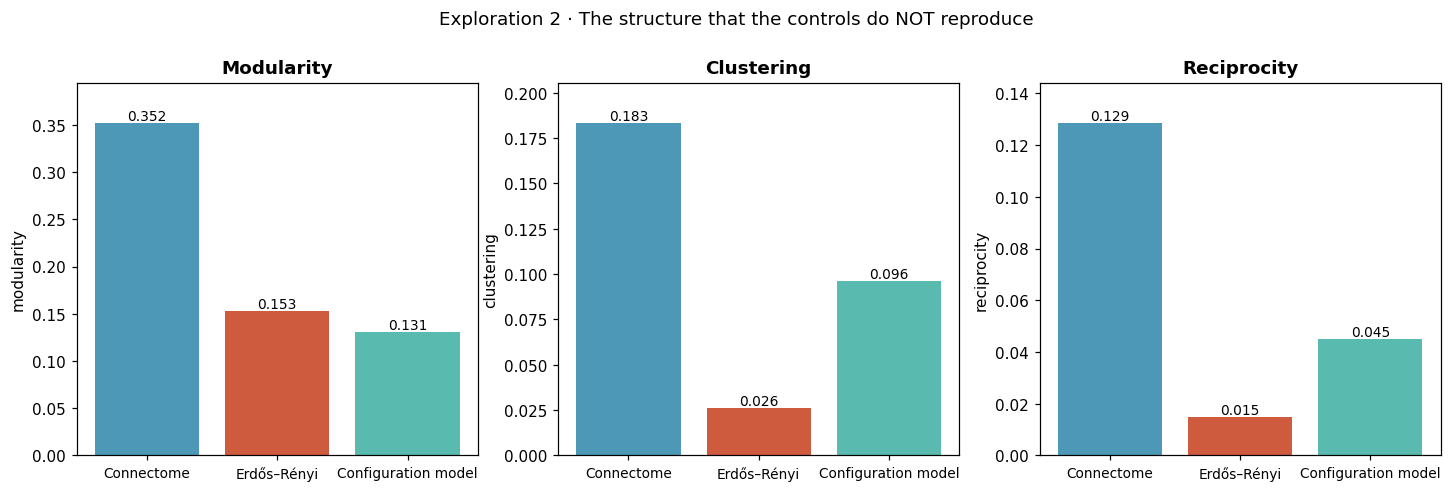

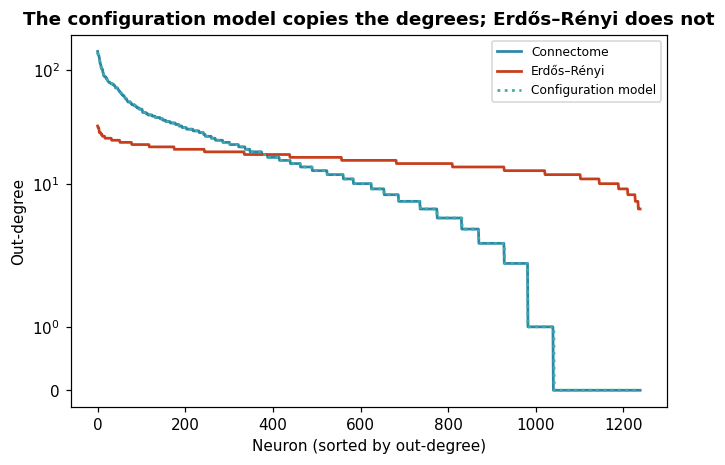

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
labels = {'connectome':'Connectome','er':'Erdős–Rényi','configuration':'Configuration model'}
colors = [BLUE, RED, GREEN]
for a, col in zip(ax, ['modularity','clustering','reciprocity']):
    a.bar(range(3), table[col].values, color=colors, alpha=.85)
    a.set_xticks(range(3)); a.set_xticklabels([labels[t] for t in table.index], fontsize=9, rotation=0)
    a.set_title(col.capitalize()); a.set_ylabel(col)
    a.margins(y=0.12)
    for i,v in enumerate(table[col].values):
        a.text(i, v, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
fig.suptitle('Exploration 2 · The structure that the controls do NOT reproduce', y=1.03)
fig.savefig(FIGURES/'02-control-topologies-structure.png'); plt.show()

gs_bio = np.bincount(C.pre, minlength=C.N)
fig, ax = plt.subplots(figsize=(7,4.4))
for topo,c,ls in zip(['connectome','er','configuration'], colors, ['-', '-', ':']):
    wiring = C.wiring(topo, seed=0)
    gs = np.bincount(np.concatenate([v[0] for v in wiring.values()]), minlength=C.N)
    ax.plot(np.sort(gs)[::-1], color=c, lw=1.8, ls=ls, label=labels[topo])
ax.set_yscale('symlog'); ax.set_xlabel('Neuron (sorted by out-degree)')
ax.set_ylabel('Out-degree'); ax.legend(fontsize=8)
ax.set_title('The configuration model copies the degrees; Erdős–Rényi does not')
fig.savefig(FIGURES/'02-out-degree-distribution.png'); plt.show()

The three networks have exactly the same number of connections of each polarity, **20,059** in total, and their weights come from the same distribution, yet only the biological one is highly modular. The configuration model copies the degree of every neuron and still keeps only 37 % of the modularity (0.1307 against 0.3524). It even falls below the Erdős–Rényi graph (0.1528). The structure of the connectome is therefore not just a matter of a few neurons concentrating many connections. Clustering tells the same story (0.1835 in the connectome, 0.0963 in the configuration model, 0.0260 in Erdős–Rényi), and so does reciprocity (0.1287, 0.0450 and 0.0147).

Erdős–Rényi shows 19,994 edges instead of 20,059 because the connections are drawn separately for each polarity. **65 pairs of neurons receive two connections of different polarity**, and the directed graph counts each such pair as one edge. The number of simulated connections is still the same in the three networks, and that is what makes the comparison fair.

The copy of the degrees is **almost** exact. The endpoint shuffle rejects self-connections and repeated pairs, and the few endpoints it cannot place are closed with random valid targets. The correlation of out-degrees with the connectome is 0.999983, and 10 of the 1,239 neurons deviate, by 3 connections at most (the largest out-degree becomes 141 instead of 144). The second figure shows the sorted out-degrees. The connectome (solid blue) and the configuration model (dotted green) lie on top of each other, while Erdős–Rényi gives every neuron a similar number of connections.

These two topologies become arms of the phase-04 experiment, that is, conditions run side by side with the connectome. They are not just an illustration.

## 8. Distribution of synaptic weights

The weight of a connection is its number of synaptic contacts. The next cell summarizes how the weights are distributed and plots them next to the split of connections by polarity.

Synaptic weight (contacts per connection): n=20,059
  minimum        5.00
  median        10.00
  mean          16.85
  p95           51.00
  p99          105.00
  maximum      347.00
  skewness: 4.68  (pronounced long tail)


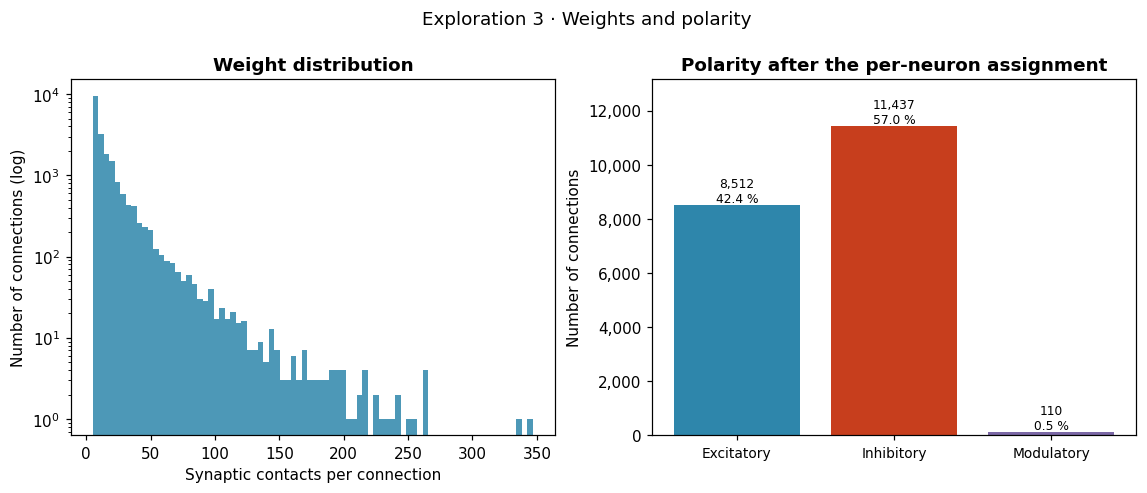

In [18]:
w = C.raw_weight
print(f'Synaptic weight (contacts per connection): n={len(w):,}')
for k,v in [('minimum',w.min()),('median',np.median(w)),('mean',w.mean()),
            ('p95',np.percentile(w,95)),('p99',np.percentile(w,99)),('maximum',w.max())]:
    print(f'  {k:10s} {v:8.2f}')
print(f'  skewness: {float(pd.Series(w).skew()):.2f}  (pronounced long tail)')

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.2))
ax[0].hist(w, bins=80, color=BLUE, alpha=.85)
ax[0].set_yscale('log'); ax[0].set_xlabel('Synaptic contacts per connection')
ax[0].set_ylabel('Number of connections (log)'); ax[0].set_title('Weight distribution')
pol_colors = {'Excitatory':BLUE,'Inhibitory':RED,'Modulatory':PURPLE}
counts = {p:int(m.sum()) for p,m in C.mask.items()}
ax[1].bar(range(len(counts)), list(counts.values()),
          color=[pol_colors[k] for k in counts])
ax[1].set_xticks(range(len(counts))); ax[1].set_xticklabels(list(counts), fontsize=9)
ax[1].set_ylabel('Number of connections'); ax[1].set_title('Polarity after the per-neuron assignment')
ax[1].margins(y=0.15); ax[1].yaxis.set_major_formatter('{x:,.0f}')
for i,v in enumerate(counts.values()):
    ax[1].text(i, v, f'{v:,}\n{100*v/sum(counts.values()):.1f} %', ha='center', va='bottom', fontsize=8)
fig.suptitle('Exploration 3 · Weights and polarity', y=1.03)
fig.savefig(FIGURES/'02-weights-and-polarity.png'); plt.show()

The weights have a long tail. The median connection has 10 contacts, the mean is 16.85 and the strongest connection has 347, about 35 times the median (skewness 4.68). How much of that tail the simulation keeps, and on what scale, is a modeling choice that phase 03 makes.

In the right panel, 57.0 % of the connections are inhibitory, 42.4 % excitatory and only 0.5 % (110 connections) modulatory. Modulatory connections are rare because the per-neuron assignment averages out the serotonin, dopamine and octopamine labels that the classifier scatters over single synapses.

## 9. Summary of the phase

| Decision | Value | Reason |
|---|---|---|
| Snapshot | FlyWire v783 | neuron and synapse counts checked against the publication |
| JO definition | `sensory / mechanosensory / auditory` | JO-A + JO-B; leaves out the gravity and wind subgroups |
| Partners | postsynaptic partners of the JO neurons | keeps the network anchored to the sensory input |
| Connection weight | sum of contacts over neuropils | a connection split across neuropils is still one connection |
| Threshold | ≥ 5 contacts | threshold of Dorkenwald et al. (2024) and default of Codex; cost measured (−31.6 % of the 393 JO neurons) |
| Neurotransmitter | weighted majority **per neuron** | follows Dale's principle and removes the dependence on row order |
| JO afferents | cholinergic prior | most JO neurons are cholinergic, and the classifier mislabels some sensory neurons |
| Input layer | JO neurons with out-degree > 0 | the stimulus has to be able to propagate |
| Channel mapping | anchored to the JO-B / JO-A subtypes | measured projection segregation, 4.84× within against between subtypes |
| Controls | Erdős–Rényi and configuration model | isolate the number of connections and the degree sequence |

The files `data/processed/jo_nodes.csv`, `jo_edges.csv` and `jo_meta.json` are the single source of truth for phases 03 to 06. The [results of this phase](results.md) and its [research log](research-log.md) discuss them in more detail.

## References

- Azevedo, A. W., & Wilson, R. I. (2017). Active mechanisms of vibration encoding and frequency filtering in central mechanosensory neurons. *Neuron, 96*(2), 446–460.e9. https://doi.org/10.1016/j.neuron.2017.09.004
- Blondel, V. D., Guillaume, J.-L., Lambiotte, R., & Lefebvre, E. (2008). Fast unfolding of communities in large networks. *Journal of Statistical Mechanics: Theory and Experiment, 2008*(10), Article P10008. https://doi.org/10.1088/1742-5468/2008/10/P10008
- Buhmann, J., Sheridan, A., Malin-Mayor, C., Schlegel, P., Gerhard, S., Kazimiers, T., Krause, R., Nguyen, T. M., Heinrich, L., Lee, W.-C. A., Wilson, R., Saalfeld, S., Jefferis, G. S. X. E., Bock, D. D., Turaga, S. C., Cook, M., & Funke, J. (2021). Automatic detection of synaptic partners in a whole-brain *Drosophila* electron microscopy data set. *Nature Methods, 18*(7), 771–774. https://doi.org/10.1038/s41592-021-01183-7
- Chapman, P., Clinton, J., Kerber, R., Khabaza, T., Reinartz, T., Shearer, C., & Wirth, R. (2000). *CRISP-DM 1.0: Step-by-step data mining guide*. SPSS Inc. https://web.archive.org/web/20060207174803/http://www.crisp-dm.org/CRISPWP-0800.pdf
- Deutsch, D., Matsliah, A., Crown, A., Wang, K., Dorkenwald, S., Mondal, A., Jana, S., Burke, A., Hebditch, J., Gager, J., Normand, E., Wang, M., MkKellar, C., Yu, S.-c., Sterling, A., Schlegel, P., Gerhard, S., Sterne, G., Costa, M., . . . Murthy, M. (2025). *Sexually dimorphic neurons in the Drosophila whole-brain connectome* [Preprint]. bioRxiv. https://doi.org/10.1101/2025.06.10.658788
- Dorkenwald, S., Matsliah, A., Sterling, A. R., Schlegel, P., Yu, S.-c., McKellar, C. E., Lin, A., Costa, M., Eichler, K., Yin, Y., Silversmith, W., Schneider-Mizell, C., Jordan, C. S., Brittain, D., Halageri, A., Kuehner, K., Ogedengbe, O., Morey, R., Gager, J., . . . The FlyWire Consortium. (2024). Neuronal wiring diagram of an adult brain. *Nature, 634*(8032), 124–138. https://doi.org/10.1038/s41586-024-07558-y
- Eccles, J. C. (1976). From electrical to chemical transmission in the central nervous system: The closing address of the Sir Henry Dale Centennial Symposium. *Notes and Records of the Royal Society of London, 30*(2), 219–230. https://doi.org/10.1098/rsnr.1976.0015
- Eckstein, N., Bates, A. S., Champion, A., Du, M., Yin, Y., Schlegel, P., Lu, A. K.-Y., Rymer, T., Finley-May, S., Paterson, T., Parekh, R., Dorkenwald, S., Matsliah, A., Yu, S.-C., McKellar, C., Sterling, A., Eichler, K., Costa, M., Seung, S., . . . Funke, J. (2024). Neurotransmitter classification from electron microscopy images at synaptic sites in *Drosophila melanogaster*. *Cell, 187*(10), 2574–2594.e23. https://doi.org/10.1016/j.cell.2024.03.016
- Erdős, P., & Rényi, A. (1959). On random graphs I. *Publicationes Mathematicae Debrecen, 6*(3–4), 290–297. https://doi.org/10.5486/PMD.1959.6.3-4.12
- Fayyad, U., Piatetsky-Shapiro, G., & Smyth, P. (1996). From data mining to knowledge discovery in databases. *AI Magazine, 17*(3), 37–54. https://doi.org/10.1609/aimag.v17i3.1230
- Heinrich, L., Funke, J., Pape, C., Nunez-Iglesias, J., & Saalfeld, S. (2018). Synaptic cleft segmentation in non-isotropic volume electron microscopy of the complete *Drosophila* brain. In *Medical image computing and computer assisted intervention – MICCAI 2018* (pp. 317–325). Springer. https://doi.org/10.1007/978-3-030-00934-2_36
- Ishikawa, Y., Okamoto, N., Nakamura, M., Kim, H., & Kamikouchi, A. (2017). Anatomic and physiologic heterogeneity of subgroup-A auditory sensory neurons in fruit flies. *Frontiers in Neural Circuits, 11*, Article 46. https://doi.org/10.3389/fncir.2017.00046
- Kamikouchi, A., Inagaki, H. K., Effertz, T., Hendrich, O., Fiala, A., Göpfert, M. C., & Ito, K. (2009). The neural basis of *Drosophila* gravity-sensing and hearing. *Nature, 458*(7235), 165–171. https://doi.org/10.1038/nature07810
- Liu, W. W., & Wilson, R. I. (2013). Glutamate is an inhibitory neurotransmitter in the *Drosophila* olfactory system. *Proceedings of the National Academy of Sciences, 110*(25), 10294–10299. https://doi.org/10.1073/pnas.1220560110
- Matsliah, A., Sterling, A. R., Dorkenwald, S., Kuehner, K., Morey, R., Seung, H. S., & Murthy, M. (2023). *Codex: Connectome Data Explorer* [Preprint]. ResearchGate. https://doi.org/10.13140/RG.2.2.35928.67844
- Matsliah, A., Yu, S.-c., Kruk, K., Bland, D., Burke, A. T., Gager, J., Hebditch, J., Silverman, B., Willie, K. P., Willie, R., Sorek, M., Sterling, A. R., Kind, E., Garner, D., Sancer, G., Wernet, M. F., Kim, S. S., Murthy, M., Seung, H. S., & The FlyWire Consortium. (2024). Neuronal parts list and wiring diagram for a visual system. *Nature, 634*(8032), 166–180. https://doi.org/10.1038/s41586-024-07981-1
- Matsuo, E., Yamada, D., Ishikawa, Y., Asai, T., Ishimoto, H., & Kamikouchi, A. (2014). Identification of novel vibration- and deflection-sensitive neuronal subgroups in Johnston’s organ of the fruit fly. *Frontiers in Physiology, 5*, Article 179. https://doi.org/10.3389/fphys.2014.00179
- Molloy, M., & Reed, B. (1995). A critical point for random graphs with a given degree sequence. *Random Structures & Algorithms, 6*(2–3), 161–180. https://doi.org/10.1002/rsa.3240060204
- Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences, 103*(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103
- Newman, M. E. J., Strogatz, S. H., & Watts, D. J. (2001). Random graphs with arbitrary degree distributions and their applications. *Physical Review E, 64*(2), Article 026118. https://doi.org/10.1103/PhysRevE.64.026118
- Pézier, A. P., Jezzini, S. H., Bacon, J. P., & Blagburn, J. M. (2016). Shaking B mediates synaptic coupling between auditory sensory neurons and the giant fiber of *Drosophila melanogaster*. *PLOS ONE, 11*(4), Article e0152211. https://doi.org/10.1371/journal.pone.0152211
- Schlegel, P., Yin, Y., Bates, A. S., Dorkenwald, S., Eichler, K., Brooks, P., Han, D. S., Gkantia, M., dos Santos, M., Munnelly, E. J., Badalamente, G., Serratosa Capdevila, L., Sane, V. A., Fragniere, A. M. C., Kiassat, L., Pleijzier, M. W., Stürner, T., Tamimi, I. F. M., Dunne, C. R., . . . Jefferis, G. S. X. E. (2024). Whole-brain annotation and multi-connectome cell typing of *Drosophila*. *Nature, 634*(8032), 139–152. https://doi.org/10.1038/s41586-024-07686-5
- Svensson, E., Apergis-Schoute, J., Burnstock, G., Nusbaum, M. P., Parker, D., & Schiöth, H. B. (2019). General principles of neuronal co-transmission: Insights from multiple model systems. *Frontiers in Neural Circuits, 12*, Article 117. https://doi.org/10.3389/fncir.2018.00117
- Yorozu, S., Wong, A., Fischer, B. J., Dankert, H., Kernan, M. J., Kamikouchi, A., Ito, K., & Anderson, D. J. (2009). Distinct sensory representations of wind and near-field sound in the *Drosophila* brain. *Nature, 458*(7235), 201–205. https://doi.org/10.1038/nature07843
- Zheng, Z., Lauritzen, J. S., Perlman, E., Robinson, C. G., Nichols, M., Milkie, D., Torrens, O., Price, J., Fisher, C. B., Sharifi, N., Calle-Schuler, S. A., Kmecova, L., Ali, I. J., Karsh, B., Trautman, E. T., Bogovic, J. A., Hanslovsky, P., Jefferis, G. S. X. E., Kazhdan, M., . . . Bock, D. D. (2018). A complete electron microscopy volume of the brain of adult *Drosophila melanogaster*. *Cell, 174*(3), 730–743.e22. https://doi.org/10.1016/j.cell.2018.06.019